# AML 04 — Coordinate Regression

**Objective.** Member 4's Phase 1 AML deliverable: predict `LONGITUDE` and `LATITUDE`
from Wi-Fi signal-strength features using a Random Forest regressor, with
Member 1's shared preprocessing, feature definitions, and data split.

## Pipeline summary

| Step | Description |
|------|-------------|
| 1 | Load Member 1's processed CSV files and validate schemas |
| 2 | Separate predictors, targets, and identifiers |
| 3 | Train a baseline Random Forest regressor |
| 4 | Hyperparameter tuning on internal validation only |
| 5 | Freeze configuration, evaluate once on held-out validation |
| 6 | Actual-vs-predicted and spatial error visualisations |
| 7 | Export CSV artifacts |

## Coordinate reference system

The UJIIndoorLoc dataset stores `LONGITUDE` and `LATITUDE` as **UTM Easting and
Northing coordinates** (WGS 84 datum), measured in **metres**. Despite the column
names, these are *not* geographic degrees. The authoritative dataset description
(Torres-Sospedra et al., 2014) confirms that the values are UTM-projected
coordinates. Member 1's handoff notes that the repository itself does not
document units or projection; this notebook relies on the published dataset
specification for the metre-unit claim. All reported errors are in metres.

In [1]:
# ── 0. Imports, versions, and reproducibility ─────────────────────────
from pathlib import Path
import platform
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.multioutput import MultiOutputRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"Python : {platform.python_version()} ({sys.executable})")
print(f"NumPy  : {np.__version__}")
print(f"pandas : {pd.__version__}")
print(f"sklearn: {__import__('sklearn').__version__}")
print(f"seaborn: {sns.__version__}")
print(f"matplotlib: {plt.matplotlib.__version__}")

Python : 3.14.7 (/Users/abhimansingh/Desktop/Signal2Space/.venv/bin/python3.14)
NumPy  : 2.5.4
pandas : 3.0.6
sklearn: 1.9.1
seaborn: 0.13.2
matplotlib: 3.11.2


In [2]:
# ── 1. Locate repository root ─────────────────────────────────────────

def find_project_root(start=None):
    """Walk up from *start* (default: cwd) until the repo markers are found."""
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if (
            (parent / "data/raw/trainingData.csv").is_file()
            and (parent / "Machine Learning Pipeline").is_dir()
        ):
            return parent
    raise FileNotFoundError(
        "Could not locate the Signal2Space repository root "
        "from the current working directory."
    )

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

TRAIN_PATH = PROCESSED_DIR / "aml_internal_train_features.csv"
IVAL_PATH  = PROCESSED_DIR / "aml_internal_validation_features.csv"
HELDOUT_PATH = PROCESSED_DIR / "aml_heldout_validation_features.csv"

for p in (TRAIN_PATH, IVAL_PATH, HELDOUT_PATH):
    assert p.is_file(), f"Missing required input: {p}"

print(f"Project root : {PROJECT_ROOT}")
print(f"Processed dir: {PROCESSED_DIR}")

Project root : /Users/abhimansingh/Desktop/Signal2Space
Processed dir: /Users/abhimansingh/Desktop/Signal2Space/data/processed


## 1. Load data and validate schemas

In [3]:
# ── 1a. Read the three CSV splits ─────────────────────────────────────
train_df = pd.read_csv(TRAIN_PATH)
ival_df  = pd.read_csv(IVAL_PATH)
heldout_df = pd.read_csv(HELDOUT_PATH)

print(f"Internal train      : {train_df.shape}")
print(f"Internal validation : {ival_df.shape}")
print(f"Held-out validation : {heldout_df.shape}")

Internal train      : (16085, 1057)
Internal validation : (3852, 1057)
Held-out validation : (1111, 1057)


In [4]:
# ── 1b. Reconstruct Member 1 column lists and validate ────────────────

# Discover WAP columns from the actual header
all_columns = train_df.columns.tolist()
AP_COLUMNS = sorted(
    [c for c in all_columns if re.fullmatch(r"RSSI_Z__WAP\d+", c)],
    key=lambda c: int(re.search(r"\d+", c.split("WAP")[1]).group()),
)
SEEN_COLUMNS = [c.replace("RSSI_Z__", "SEEN__") for c in AP_COLUMNS]
SUMMARY_COLUMNS = ["n_heard", "max_rssi_dbm", "mean_rssi_dbm",
                   "std_rssi_dbm", "n_strong", "top1_ap_index"]

FEATURE_COLUMNS = AP_COLUMNS + SEEN_COLUMNS + SUMMARY_COLUMNS

TARGET_COLUMNS = ["LONGITUDE", "LATITUDE"]
ALL_TARGET_COLUMNS = ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
METADATA_COLUMNS = ["ROW_ID", "SOURCE_PARTITION", "SPACEID",
                    "RELATIVEPOSITION", "USERID", "PHONEID", "TIMESTAMP"]

# Verify required columns exist in all splits
for name, df in [("train", train_df), ("ival", ival_df), ("heldout", heldout_df)]:
    missing_feat = [c for c in FEATURE_COLUMNS if c not in df.columns]
    missing_tgt  = [c for c in TARGET_COLUMNS if c not in df.columns]
    missing_meta = [c for c in METADATA_COLUMNS if c not in df.columns]
    assert not missing_feat, f"{name}: missing features {missing_feat}"
    assert not missing_tgt, f"{name}: missing targets {missing_tgt}"
    assert not missing_meta, f"{name}: missing metadata {missing_meta}"

# Verify column order is identical
assert train_df.columns.tolist() == ival_df.columns.tolist(), \
    "Column mismatch between train and ival"
assert train_df.columns.tolist() == heldout_df.columns.tolist(), \
    "Column mismatch between train and heldout"

print(f"WAP feature pairs : {len(AP_COLUMNS)} (RSSI_Z + SEEN = {2 * len(AP_COLUMNS)})")
print(f"Summary features  : {len(SUMMARY_COLUMNS)}")
print(f"Total predictors  : {len(FEATURE_COLUMNS)}")
print(f"Targets           : {TARGET_COLUMNS}")

WAP feature pairs : 520 (RSSI_Z + SEEN = 1040)
Summary features  : 6
Total predictors  : 1046
Targets           : ['LONGITUDE', 'LATITUDE']


## 2. Prepare predictor matrices, targets, and identifiers

Only `FEATURE_COLUMNS` are used as predictors. All targets (`BUILDINGID`,
`FLOOR`, `LONGITUDE`, `LATITUDE`) and metadata/identifiers are excluded from
the predictor matrix. Identifiers are retained separately for traceability.

In [5]:
# ── 2. Separate features, targets, identifiers ─────────────────────────

X_train = train_df[FEATURE_COLUMNS].values
y_train = train_df[TARGET_COLUMNS].values  # shape (n, 2): [LONGITUDE, LATITUDE]

X_ival = ival_df[FEATURE_COLUMNS].values
y_ival = ival_df[TARGET_COLUMNS].values

X_heldout = heldout_df[FEATURE_COLUMNS].values
y_heldout = heldout_df[TARGET_COLUMNS].values

# Retain identifiers for heldout predictions CSV
heldout_ids = heldout_df[["ROW_ID", "SOURCE_PARTITION"]].copy()
ival_ids = ival_df[["ROW_ID", "SOURCE_PARTITION"]].copy()

# ── Sanity checks ─────────────────────────────────────────────────────
# No target or metadata leakage
forbidden = set(ALL_TARGET_COLUMNS + METADATA_COLUMNS)
used_features = set(FEATURE_COLUMNS)
assert not (used_features & forbidden), \
    f"Leakage: {used_features & forbidden} in predictors"

# No NaN/inf in features or targets
for label, arr in [("X_train", X_train), ("X_ival", X_ival),
                   ("X_heldout", X_heldout)]:
    assert np.isfinite(arr).all(), f"{label} has non-finite values"
for label, arr in [("y_train", y_train), ("y_ival", y_ival),
                   ("y_heldout", y_heldout)]:
    assert np.isfinite(arr).all(), f"{label} has non-finite values"

print("Predictor / target shapes:")
print(f"  Train   : X={X_train.shape}, y={y_train.shape}")
print(f"  IVal    : X={X_ival.shape},  y={y_ival.shape}")
print(f"  Heldout : X={X_heldout.shape}, y={y_heldout.shape}")

# Coordinate ranges (UTM metres)
for i, col in enumerate(TARGET_COLUMNS):
    all_vals = np.concatenate([y_train[:, i], y_ival[:, i], y_heldout[:, i]])
    print(f"  {col}: [{all_vals.min():.2f}, {all_vals.max():.2f}]")

Predictor / target shapes:
  Train   : X=(16085, 1046), y=(16085, 2)
  IVal    : X=(3852, 1046),  y=(3852, 2)
  Heldout : X=(1111, 1046), y=(1111, 2)
  LONGITUDE: [-7695.94, -7299.79]
  LATITUDE: [4864745.75, 4865017.36]


## 3. Baseline Random Forest regressor

**Model family.** `RandomForestRegressor` from scikit-learn is chosen for its
native multi-output support (predicting both LONGITUDE and LATITUDE jointly),
robustness to feature scale, and interpretability. scikit-learn's
`RandomForestRegressor` supports multi-output natively by building each tree
to predict both targets simultaneously, so no `MultiOutputRegressor` wrapper
is needed.

**Baseline configuration.** 100 trees, no depth limit, `min_samples_leaf=1`,
`random_state=42`.

In [6]:
# ── 3. Baseline model ─────────────────────────────────────────────────

baseline_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

baseline_rf.fit(X_train, y_train)
print("Baseline Random Forest fitted.")

y_ival_pred_base = baseline_rf.predict(X_ival)


def compute_metrics(y_true, y_pred, target_names=TARGET_COLUMNS):
    """Compute per-axis MAE and mean Euclidean distance.

    Returns
    -------
    dict with keys:
      - 'mae_<col>' : Mean Absolute Error for each target column (metres)
      - 'mean_euclidean_error' : Mean of sqrt((Δlon)² + (Δlat)²)  (metres)
      - 'median_euclidean_error' : Median Euclidean distance (metres)
      - 'p75_euclidean_error' : 75th percentile Euclidean distance (metres)
      - 'p95_euclidean_error' : 95th percentile Euclidean distance (metres)
    """
    result = {}
    for i, col in enumerate(target_names):
        result[f"mae_{col}"] = mean_absolute_error(y_true[:, i], y_pred[:, i])
    # Euclidean distance between actual and predicted 2D positions
    euclidean = np.sqrt(np.sum((y_true - y_pred) ** 2, axis=1))
    result["mean_euclidean_error"] = euclidean.mean()
    result["median_euclidean_error"] = np.median(euclidean)
    result["p75_euclidean_error"] = np.percentile(euclidean, 75)
    result["p95_euclidean_error"] = np.percentile(euclidean, 95)
    return result


baseline_metrics = compute_metrics(y_ival, y_ival_pred_base)
print("\nBaseline — Internal Validation Metrics")
print("="*50)
for k, v in baseline_metrics.items():
    print(f"  {k:30s}: {v:10.4f} m")

Baseline Random Forest fitted.

Baseline — Internal Validation Metrics
  mae_LONGITUDE                 :     6.4164 m
  mae_LATITUDE                  :     5.3595 m
  mean_euclidean_error          :     9.2561 m
  median_euclidean_error        :     6.5083 m
  p75_euclidean_error           :    11.4835 m
  p95_euclidean_error           :    26.0250 m


## 4. Hyperparameter tuning

Tuning uses **only** the internal-training split (to fit) and the
internal-validation split (to score). The held-out file has not been opened
above this point.

**Scoring criterion.** Mean Euclidean distance (metres) on the internal
validation split. This metric captures joint 2D position error rather than
treating each axis independently.

**Search approach.** A manual grid over a small, computationally manageable
parameter space. Each configuration is deterministic via `random_state=42`.

In [7]:
# ── 4. Hyperparameter tuning ──────────────────────────────────────────

PARAM_GRID = [
    {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 1, "max_features": "sqrt"},
    {"n_estimators": 150, "max_depth": None, "min_samples_leaf": 1, "max_features": 0.5},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1, "max_features": "sqrt"},
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 2, "max_features": 1.0},
    {"n_estimators": 200, "max_depth": 50,   "min_samples_leaf": 1, "max_features": 1.0},
    {"n_estimators": 150, "max_depth": 50,   "min_samples_leaf": 1, "max_features": 1.0},
]

tuning_results = []

for i, params in enumerate(PARAM_GRID):
    rf = RandomForestRegressor(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    rf.fit(X_train, y_train)
    y_ival_pred = rf.predict(X_ival)
    metrics = compute_metrics(y_ival, y_ival_pred)
    row = {**params, **metrics}
    tuning_results.append(row)
    print(f"  Config {i+1:2d}/{len(PARAM_GRID)}: "
          f"n_est={params['n_estimators']:3d}  "
          f"depth={str(params['max_depth']):>4s}  "
          f"leaf={params['min_samples_leaf']}  "
          f"max_feat={str(params['max_features']):>4s}  "
          f"→ mean_euclid={metrics['mean_euclidean_error']:.2f} m")

tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values("mean_euclidean_error").reset_index(drop=True)
print("\nTuning results (sorted by mean Euclidean error):")
display(tuning_df)

  Config  1/10: n_est=100  depth=None  leaf=1  max_feat= 1.0  → mean_euclid=9.26 m


  Config  2/10: n_est=150  depth=None  leaf=1  max_feat= 1.0  → mean_euclid=9.20 m


  Config  3/10: n_est=200  depth=None  leaf=1  max_feat= 1.0  → mean_euclid=9.20 m


  Config  4/10: n_est=150  depth=None  leaf=2  max_feat= 1.0  → mean_euclid=9.42 m


  Config  5/10: n_est=150  depth=None  leaf=1  max_feat=sqrt  → mean_euclid=8.67 m


...

  Config  7/10: n_est=200  depth=None  leaf=1  max_feat=sqrt  → mean_euclid=8.66 m


  Config  8/10: n_est=200  depth=None  leaf=2  max_feat= 1.0  → mean_euclid=9.43 m


  Config  9/10: n_est=200  depth=  50  leaf=1  max_feat= 1.0  → mean_euclid=9.20 m


  Config 10/10: n_est=150  depth=  50  leaf=1  max_feat= 1.0  → mean_euclid=9.19 m

Tuning results (sorted by mean Euclidean error):


,n_estimators,max_depth,min_samples_leaf,max_features,mae_LONGITUDE,mae_LATITUDE,mean_euclidean_error,median_euclidean_error,p75_euclidean_error,p95_euclidean_error
0,150,NaN,1,0.5,5.914234,5.060706,8.578616,6.306672,11.091728,22.769854
1,200,NaN,1,sqrt,5.838183,5.210013,8.656748,6.823991,11.322557,20.882369
2,150,NaN,1,sqrt,5.826105,5.227708,8.674933,6.835053,11.337964,20.821107
3,150,50.0,1,1.0,6.331772,5.355073,9.191243,6.473980,11.502294,25.395268
4,150,NaN,1,1.0,6.340325,5.358414,9.200362,6.505293,11.541540,25.774157
5,200,NaN,1,1.0,6.343405,5.361017,9.202441,6.474298,11.629623,25.409552
6,200,50.0,1,1.0,6.339767,5.367377,9.203027,6.435152,11.655844,25.337478
7,100,NaN,1,1.0,6.416407,5.359463,9.256109,6.508299,11.483525,26.024995
8,150,NaN,2,1.0,6.471343,5.520461,9.417484,6.579634,11.874533,26.329107
9,200,NaN,2,1.0,6.482831,5.523150,9.429384,6.538812,11.942403,26.488860


## 5. Freeze model configuration

The configuration with the lowest mean Euclidean distance on the internal
validation split is selected **now**. Nothing below this cell revises features,
model family, hyperparameters, or scoring thresholds based on the held-out
data.

In [8]:
# ── 5. Select best configuration ──────────────────────────────────────

best_row = tuning_df.iloc[0]
BEST_PARAMS = {
    "n_estimators": int(best_row["n_estimators"]),
    "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
    "max_features": best_row["max_features"],
}

print("Selected configuration:")
for k, v in BEST_PARAMS.items():
    print(f"  {k}: {v}")
print(f"\nInternal validation mean Euclidean error: "
      f"{best_row['mean_euclidean_error']:.4f} m")

Selected configuration:
  n_estimators: 150
  max_depth: None
  min_samples_leaf: 1
  max_features: 0.5

Internal validation mean Euclidean error: 8.5786 m


In [9]:
# ── 5b. Retrain with selected configuration ──────────────────────────
# Retrain on the same internal-training split with the chosen parameters.
# (Needed because the tuning loop does not retain each fitted model.)

final_rf = RandomForestRegressor(
    **BEST_PARAMS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_rf.fit(X_train, y_train)

# Reproduce internal-validation metrics to confirm determinism
y_ival_pred_final = final_rf.predict(X_ival)
ival_metrics = compute_metrics(y_ival, y_ival_pred_final)

print("Internal validation — Tuned model")
print("=" * 50)
for k, v in ival_metrics.items():
    print(f"  {k:30s}: {v:10.4f} m")

Internal validation — Tuned model
  mae_LONGITUDE                 :     5.9142 m
  mae_LATITUDE                  :     5.0607 m
  mean_euclidean_error          :     8.5786 m
  median_euclidean_error        :     6.3067 m
  p75_euclidean_error           :    11.0917 m
  p95_euclidean_error           :    22.7699 m


## 6. Final held-out evaluation

The held-out file is used for the first time in this notebook **here**,
strictly after the configuration freeze. Its schema was validated above
but no predictions on it were generated until now.

In [10]:
# ── 6. Held-out evaluation ────────────────────────────────────────────

y_heldout_pred = final_rf.predict(X_heldout)

# Verify prediction shape and finiteness
assert y_heldout_pred.shape == y_heldout.shape, \
    f"Shape mismatch: {y_heldout_pred.shape} vs {y_heldout.shape}"
assert np.isfinite(y_heldout_pred).all(), "Non-finite predictions detected"

heldout_metrics = compute_metrics(y_heldout, y_heldout_pred)

print("Held-out Validation — Final Metrics")
print("=" * 55)
for k, v in heldout_metrics.items():
    print(f"  {k:30s}: {v:10.4f} m")

print("\n── Metric definitions ──")
print("  mae_LONGITUDE        : mean(|actual_lon − pred_lon|)  [metres]")
print("  mae_LATITUDE         : mean(|actual_lat − pred_lat|)  [metres]")
print("  mean_euclidean_error : mean(√((Δlon)² + (Δlat)²))    [metres]")
print("  median_euclidean_error: median of the above distances [metres]")
print("  p75/p95              : 75th / 95th percentile         [metres]")

Held-out Validation — Final Metrics
  mae_LONGITUDE                 :     8.0966 m
  mae_LATITUDE                  :     6.8064 m
  mean_euclidean_error          :    11.5836 m
  median_euclidean_error        :     7.4884 m
  p75_euclidean_error           :    13.6752 m
  p95_euclidean_error           :    36.2126 m

── Metric definitions ──
  mae_LONGITUDE        : mean(|actual_lon − pred_lon|)  [metres]
  mae_LATITUDE         : mean(|actual_lat − pred_lat|)  [metres]
  mean_euclidean_error : mean(√((Δlon)² + (Δlat)²))    [metres]
  median_euclidean_error: median of the above distances [metres]
  p75/p95              : 75th / 95th percentile         [metres]


## 7. Actual-versus-predicted plots

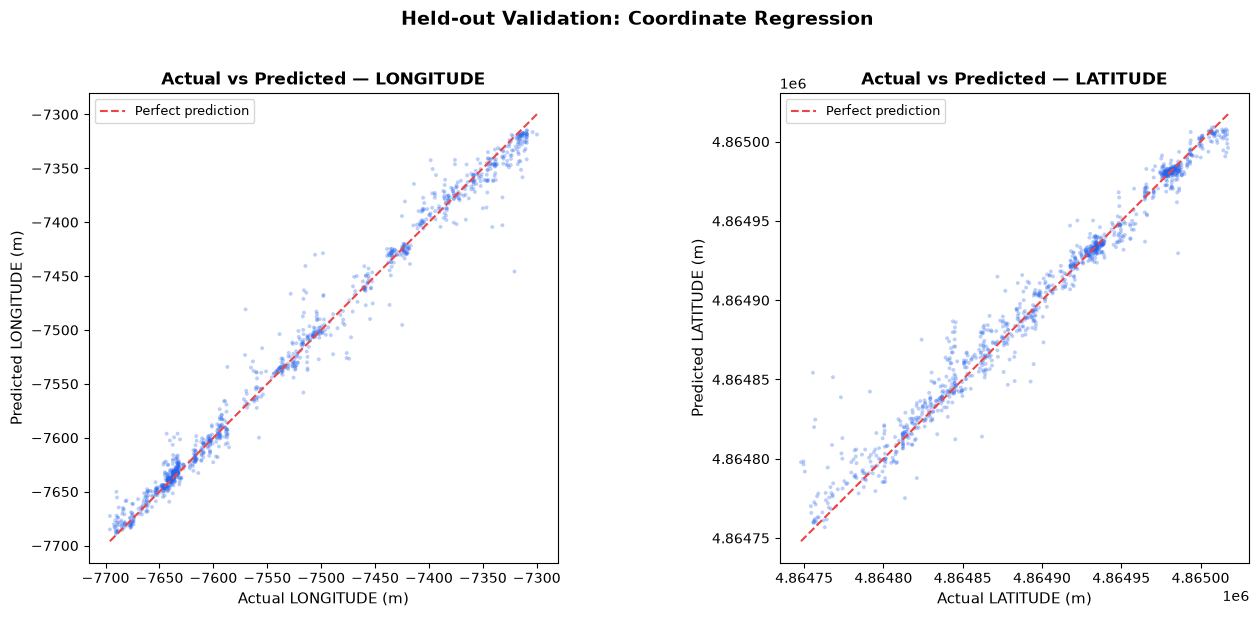

In [11]:
# ── 7a. Actual vs predicted scatter for each coordinate axis ──────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax_idx, (col_idx, col_name) in enumerate(zip(range(2), TARGET_COLUMNS)):
    ax = axes[ax_idx]
    actual = y_heldout[:, col_idx]
    predicted = y_heldout_pred[:, col_idx]

    ax.scatter(actual, predicted, alpha=0.3, s=8, color="#2563eb", edgecolors="none")

    # Reference line
    lo = min(actual.min(), predicted.min())
    hi = max(actual.max(), predicted.max())
    ax.plot([lo, hi], [lo, hi], "--", color="#ef4444", linewidth=1.5,
            label="Perfect prediction")

    ax.set_xlabel(f"Actual {col_name} (m)", fontsize=11)
    ax.set_ylabel(f"Predicted {col_name} (m)", fontsize=11)
    ax.set_title(f"Actual vs Predicted — {col_name}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=9)
    ax.set_aspect("equal", adjustable="box")

fig.suptitle("Held-out Validation: Coordinate Regression", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

## 8. Spatial error visualisations

Two plots:
1. **Error heatmap.** Actual sample positions (LONGITUDE vs LATITUDE) coloured
   by Euclidean prediction error.
2. **Displacement segments.** Lines from actual to predicted positions showing
   direction and magnitude of each prediction error.

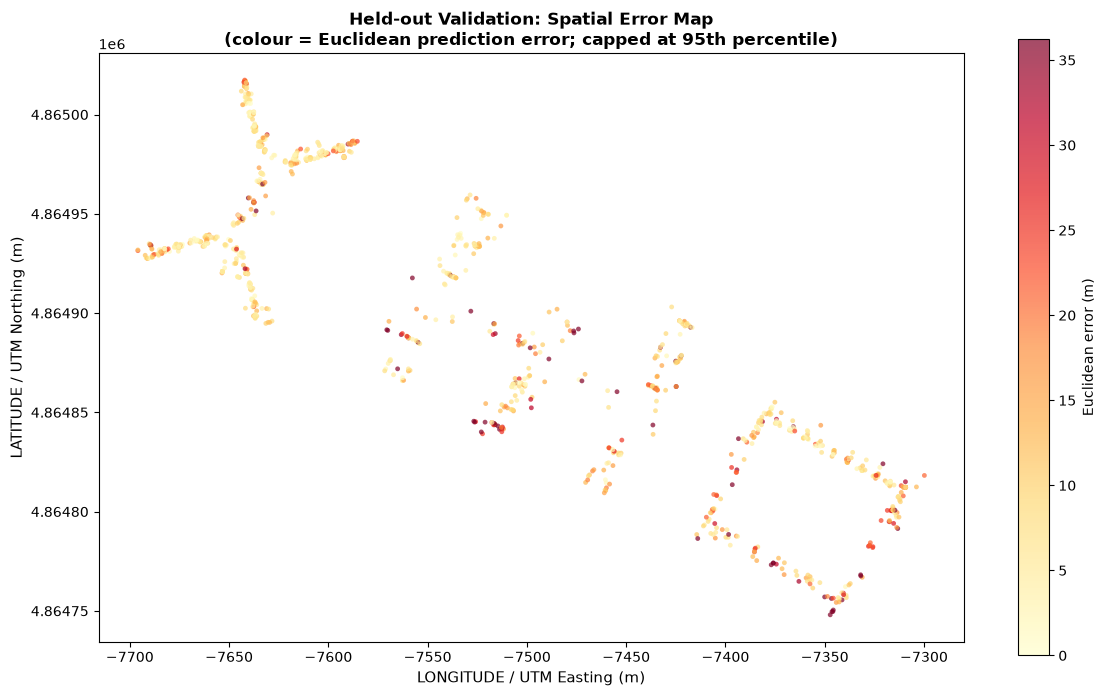

In [12]:
# ── 8a. Spatial error map (actual positions coloured by error) ────────

euclidean_errors = np.sqrt(np.sum((y_heldout - y_heldout_pred) ** 2, axis=1))

fig, ax = plt.subplots(figsize=(12, 8))
sc = ax.scatter(
    y_heldout[:, 0],   # LONGITUDE (Easting)
    y_heldout[:, 1],   # LATITUDE  (Northing)
    c=euclidean_errors,
    cmap="YlOrRd",
    s=12,
    alpha=0.7,
    edgecolors="none",
    vmin=0,
    vmax=np.percentile(euclidean_errors, 95),
)
cbar = fig.colorbar(sc, ax=ax, shrink=0.8, label="Euclidean error (m)")
ax.set_xlabel("LONGITUDE / UTM Easting (m)", fontsize=11)
ax.set_ylabel("LATITUDE / UTM Northing (m)", fontsize=11)
ax.set_title("Held-out Validation: Spatial Error Map\n"
             "(colour = Euclidean prediction error; capped at 95th percentile)",
             fontsize=12, fontweight="bold")
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

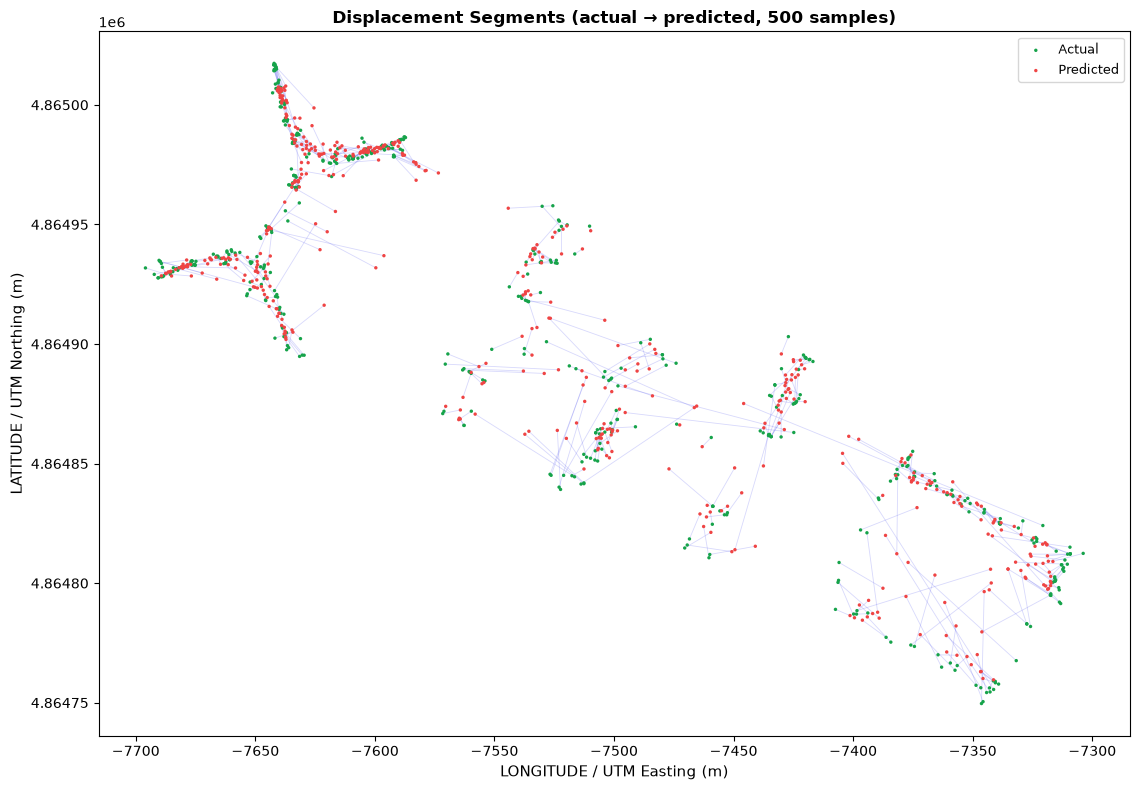

In [13]:
# ── 8b. Displacement segments (actual → predicted) ────────────────────

fig, ax = plt.subplots(figsize=(12, 8))

# Subsample for visual clarity when many points overlap
rng = np.random.RandomState(RANDOM_STATE)
n_show = min(500, len(y_heldout))
idx = rng.choice(len(y_heldout), size=n_show, replace=False)

for i in idx:
    ax.plot(
        [y_heldout[i, 0], y_heldout_pred[i, 0]],
        [y_heldout[i, 1], y_heldout_pred[i, 1]],
        color="#6366f1", alpha=0.25, linewidth=0.6,
    )

ax.scatter(y_heldout[idx, 0], y_heldout[idx, 1], s=6, c="#16a34a",
           label="Actual", zorder=3, edgecolors="none")
ax.scatter(y_heldout_pred[idx, 0], y_heldout_pred[idx, 1], s=6, c="#ef4444",
           label="Predicted", zorder=3, edgecolors="none")

ax.set_xlabel("LONGITUDE / UTM Easting (m)", fontsize=11)
ax.set_ylabel("LATITUDE / UTM Northing (m)", fontsize=11)
ax.set_title(f"Displacement Segments (actual → predicted, {n_show} samples)",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

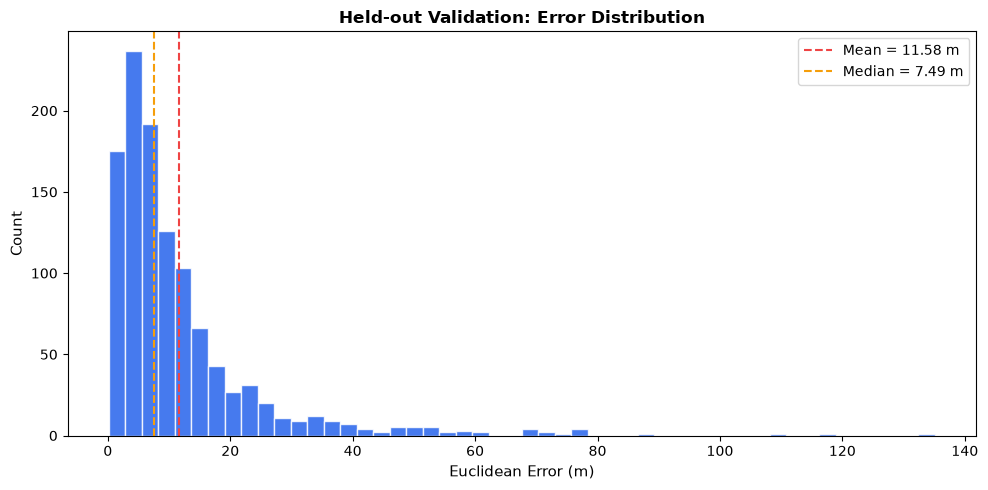

In [14]:
# ── 8c. Error distribution histogram ─────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(euclidean_errors, bins=50, color="#2563eb", edgecolor="white",
        alpha=0.85)
ax.axvline(heldout_metrics["mean_euclidean_error"], color="#ef4444",
           linestyle="--", linewidth=1.5,
           label=f"Mean = {heldout_metrics['mean_euclidean_error']:.2f} m")
ax.axvline(heldout_metrics["median_euclidean_error"], color="#f59e0b",
           linestyle="--", linewidth=1.5,
           label=f"Median = {heldout_metrics['median_euclidean_error']:.2f} m")
ax.set_xlabel("Euclidean Error (m)", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_title("Held-out Validation: Error Distribution", fontsize=12,
             fontweight="bold")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

## 9. Export CSV artifacts

All outputs are saved to the existing `data/processed/` directory.

In [15]:
# ── 9a. Heldout predictions CSV ──────────────────────────────────────

heldout_pred_df = heldout_ids.copy()
heldout_pred_df["LONGITUDE_TRUE"] = y_heldout[:, 0]
heldout_pred_df["LATITUDE_TRUE"]  = y_heldout[:, 1]
heldout_pred_df["LONGITUDE_PRED"] = y_heldout_pred[:, 0]
heldout_pred_df["LATITUDE_PRED"]  = y_heldout_pred[:, 1]
heldout_pred_df["ERROR_LONGITUDE"] = np.abs(y_heldout[:, 0] - y_heldout_pred[:, 0])
heldout_pred_df["ERROR_LATITUDE"]  = np.abs(y_heldout[:, 1] - y_heldout_pred[:, 1])
heldout_pred_df["EUCLIDEAN_ERROR"] = euclidean_errors

heldout_pred_path = PROCESSED_DIR / "ml_04_coordinate_heldout_predictions.csv"
heldout_pred_df.to_csv(heldout_pred_path, index=False)
print(f"Saved: {heldout_pred_path} ({len(heldout_pred_df)} rows)")
display(heldout_pred_df.head())

Saved: /Users/abhimansingh/Desktop/Signal2Space/data/processed/ml_04_coordinate_heldout_predictions.csv (1111 rows)


,ROW_ID,SOURCE_PARTITION,LONGITUDE_TRUE,LATITUDE_TRUE,LONGITUDE_PRED,LATITUDE_PRED,ERROR_LONGITUDE,ERROR_LATITUDE,EUCLIDEAN_ERROR
0,0,validationData,-7515.916799,4.864890e+06,-7483.917616,4.864878e+06,31.999183,11.354111,33.953844
1,1,validationData,-7383.867221,4.864840e+06,-7397.944833,4.864852e+06,14.077612,12.047136,18.528698
2,2,validationData,-7374.302080,4.864847e+06,-7401.830730,4.864861e+06,27.528650,14.864967,31.285681
3,3,validationData,-7365.824883,4.864843e+06,-7397.668019,4.864860e+06,31.843136,17.329764,36.253359
4,4,validationData,-7641.499303,4.864922e+06,-7647.832575,4.864920e+06,6.333272,2.866717,6.951863


In [16]:
# ── 9b. Internal validation predictions CSV ──────────────────────────

ival_euclidean_errors = np.sqrt(
    np.sum((y_ival - y_ival_pred_final) ** 2, axis=1)
)

ival_pred_df = ival_ids.copy()
ival_pred_df["LONGITUDE_TRUE"] = y_ival[:, 0]
ival_pred_df["LATITUDE_TRUE"]  = y_ival[:, 1]
ival_pred_df["LONGITUDE_PRED"] = y_ival_pred_final[:, 0]
ival_pred_df["LATITUDE_PRED"]  = y_ival_pred_final[:, 1]
ival_pred_df["ERROR_LONGITUDE"] = np.abs(y_ival[:, 0] - y_ival_pred_final[:, 0])
ival_pred_df["ERROR_LATITUDE"]  = np.abs(y_ival[:, 1] - y_ival_pred_final[:, 1])
ival_pred_df["EUCLIDEAN_ERROR"] = ival_euclidean_errors

ival_pred_path = PROCESSED_DIR / "ml_04_coordinate_internal_validation_predictions.csv"
ival_pred_df.to_csv(ival_pred_path, index=False)
print(f"Saved: {ival_pred_path} ({len(ival_pred_df)} rows)")

Saved: /Users/abhimansingh/Desktop/Signal2Space/data/processed/ml_04_coordinate_internal_validation_predictions.csv (3852 rows)


In [17]:
# ── 9c. Metrics CSV ──────────────────────────────────────────────────

metrics_rows = []

# Baseline on internal validation
metrics_rows.append({
    "split": "internal_validation",
    "model_config": "baseline",
    "n_estimators": 100,
    "max_depth": "",
    "min_samples_leaf": 1,
    "max_features": 1.0,
    "mae_LONGITUDE_m": baseline_metrics["mae_LONGITUDE"],
    "mae_LATITUDE_m": baseline_metrics["mae_LATITUDE"],
    "mean_euclidean_error_m": baseline_metrics["mean_euclidean_error"],
    "median_euclidean_error_m": baseline_metrics["median_euclidean_error"],
    "n_rows": len(y_ival),
})

# Tuned on internal validation
metrics_rows.append({
    "split": "internal_validation",
    "model_config": "tuned",
    "n_estimators": BEST_PARAMS["n_estimators"],
    "max_depth": BEST_PARAMS["max_depth"] if BEST_PARAMS["max_depth"] is not None else "",
    "min_samples_leaf": BEST_PARAMS["min_samples_leaf"],
    "max_features": BEST_PARAMS["max_features"],
    "mae_LONGITUDE_m": ival_metrics["mae_LONGITUDE"],
    "mae_LATITUDE_m": ival_metrics["mae_LATITUDE"],
    "mean_euclidean_error_m": ival_metrics["mean_euclidean_error"],
    "median_euclidean_error_m": ival_metrics["median_euclidean_error"],
    "n_rows": len(y_ival),
})

# Tuned on held-out validation
metrics_rows.append({
    "split": "heldout_validation",
    "model_config": "tuned",
    "n_estimators": BEST_PARAMS["n_estimators"],
    "max_depth": BEST_PARAMS["max_depth"] if BEST_PARAMS["max_depth"] is not None else "",
    "min_samples_leaf": BEST_PARAMS["min_samples_leaf"],
    "max_features": BEST_PARAMS["max_features"],
    "mae_LONGITUDE_m": heldout_metrics["mae_LONGITUDE"],
    "mae_LATITUDE_m": heldout_metrics["mae_LATITUDE"],
    "mean_euclidean_error_m": heldout_metrics["mean_euclidean_error"],
    "median_euclidean_error_m": heldout_metrics["median_euclidean_error"],
    "n_rows": len(y_heldout),
})

metrics_df = pd.DataFrame(metrics_rows)
metrics_path = PROCESSED_DIR / "ml_04_coordinate_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)
print(f"Saved: {metrics_path}")
display(metrics_df)

Saved: /Users/abhimansingh/Desktop/Signal2Space/data/processed/ml_04_coordinate_metrics.csv


,split,model_config,n_estimators,max_depth,min_samples_leaf,max_features,mae_LONGITUDE_m,mae_LATITUDE_m,mean_euclidean_error_m,median_euclidean_error_m,n_rows
0,internal_validation,baseline,100,,1,1.0,6.416407,5.359463,9.256109,6.508299,3852
1,internal_validation,tuned,150,,1,0.5,5.914234,5.060706,8.578616,6.306672,3852
2,heldout_validation,tuned,150,,1,0.5,8.096594,6.806426,11.583571,7.488385,1111


In [18]:
# ── 9d. Tuning results CSV ───────────────────────────────────────────

tuning_export_df = tuning_df.copy()
# Rename metrics for clarity
tuning_export_df = tuning_export_df.rename(columns={
    "mae_LONGITUDE": "mae_LONGITUDE_m",
    "mae_LATITUDE": "mae_LATITUDE_m",
    "mean_euclidean_error": "mean_euclidean_error_m",
    "median_euclidean_error": "median_euclidean_error_m",
    "p75_euclidean_error": "p75_euclidean_error_m",
    "p95_euclidean_error": "p95_euclidean_error_m",
})
tuning_path = PROCESSED_DIR / "ml_04_coordinate_tuning_results.csv"
tuning_export_df.to_csv(tuning_path, index=False)
print(f"Saved: {tuning_path} ({len(tuning_export_df)} rows)")

Saved: /Users/abhimansingh/Desktop/Signal2Space/data/processed/ml_04_coordinate_tuning_results.csv (10 rows)


## 10. Verification and summary

In [19]:
# ── 10. Post-run verification ─────────────────────────────────────────

# Verify CSV artifacts exist and reload cleanly
for path in [heldout_pred_path, ival_pred_path, metrics_path, tuning_path]:
    assert path.is_file(), f"Missing artifact: {path}"
    reloaded = pd.read_csv(path)
    print(f"  ✓ {path.name}: {reloaded.shape[0]} rows, {reloaded.shape[1]} cols")

# Verify heldout predictions alignment
hp = pd.read_csv(heldout_pred_path)
assert len(hp) == len(heldout_df), \
    f"Row count mismatch: predictions {len(hp)} vs heldout {len(heldout_df)}"
assert (hp["ROW_ID"].values == heldout_df["ROW_ID"].values).all(), \
    "ROW_ID alignment mismatch"
assert np.allclose(hp["LONGITUDE_TRUE"].values, y_heldout[:, 0]), \
    "LONGITUDE_TRUE mismatch"
assert np.allclose(hp["LATITUDE_TRUE"].values, y_heldout[:, 1]), \
    "LATITUDE_TRUE mismatch"
print("  ✓ Heldout predictions aligned with source data")

# Verify ival predictions alignment
ip = pd.read_csv(ival_pred_path)
assert len(ip) == len(ival_df), \
    f"Row count mismatch: predictions {len(ip)} vs ival {len(ival_df)}"
print("  ✓ Internal validation predictions aligned")

# Verify no Member 1/2/3 artifacts were overwritten
for existing in ["aml_internal_train_features.csv",
                 "aml_internal_validation_features.csv",
                 "aml_heldout_validation_features.csv",
                 "ml_02_building_metrics.csv",
                 "ml_02_building_heldout_predictions.csv",
                 "ml_02_building_heldout_confusion_matrix.csv",
                 "ml_02_building_internal_validation_predictions.csv",
                 "ml_03_floor_metrics.csv",
                 "ml_03_floor_heldout_predictions.csv",
                 "ml_03_floor_heldout_confusion_matrix.csv",
                 "ml_03_floor_internal_validation_predictions.csv"]:
    assert (PROCESSED_DIR / existing).is_file(), f"Missing: {existing}"
print("  ✓ All Member 1/2/3 artifacts intact")

  ✓ ml_04_coordinate_heldout_predictions.csv: 1111 rows, 9 cols
  ✓ ml_04_coordinate_internal_validation_predictions.csv: 3852 rows, 9 cols
  ✓ ml_04_coordinate_metrics.csv: 3 rows, 11 cols
  ✓ ml_04_coordinate_tuning_results.csv: 10 rows, 10 cols
  ✓ Heldout predictions aligned with source data
  ✓ Internal validation predictions aligned
  ✓ All Member 1/2/3 artifacts intact


In [20]:
# ── 10b. Summary ─────────────────────────────────────────────────────

print("="*60)
print("  ML_04 Coordinate Regression — Summary")
print("="*60)
print()
print("Model family       : Random Forest (scikit-learn RandomForestRegressor)")
print("Multi-output       : Native (both targets predicted jointly per tree)")
print(f"Selected config    : {BEST_PARAMS}")
print(f"Training rows      : {len(X_train)}")
print(f"Internal val rows  : {len(X_ival)}")
print(f"Held-out rows      : {len(X_heldout)}")
print(f"Predictor count    : {len(FEATURE_COLUMNS)}")
print(f"Targets            : {TARGET_COLUMNS}")
print(f"Coordinate units   : metres (UTM, WGS 84, per UJIIndoorLoc spec)")
print()
print("Held-out validation results:")
for k, v in heldout_metrics.items():
    print(f"  {k:30s}: {v:10.4f} m")
print()
print("Metric definitions:")
print("  mae_<axis>           = mean(|actual − predicted|) per axis")
print("  mean_euclidean_error = mean(√((Δlon)² + (Δlat)²))")
print("  All values in metres.")
print()
print("Generated CSV artifacts:")
for p in [heldout_pred_path, ival_pred_path, metrics_path, tuning_path]:
    print(f"  {p.relative_to(PROJECT_ROOT)}")
print()
print("Tuning criterion   : min mean_euclidean_error on internal validation")
print("Split protocol     : Member 1 GroupShuffleSplit(test_size=0.20, seed=42)")
print("                     Groups: (BUILDINGID, FLOOR, SPACEID)")
print("Held-out partition : Original validationData.csv (never used for tuning)")
print("Random state       : 42 (all estimators and splits)")

  ML_04 Coordinate Regression — Summary

Model family       : Random Forest (scikit-learn RandomForestRegressor)
Multi-output       : Native (both targets predicted jointly per tree)
Selected config    : {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 0.5}
Training rows      : 16085
Internal val rows  : 3852
Held-out rows      : 1111
Predictor count    : 1046
Targets            : ['LONGITUDE', 'LATITUDE']
Coordinate units   : metres (UTM, WGS 84, per UJIIndoorLoc spec)

Held-out validation results:
  mae_LONGITUDE                 :     8.0966 m
  mae_LATITUDE                  :     6.8064 m
  mean_euclidean_error          :    11.5836 m
  median_euclidean_error        :     7.4884 m
  p75_euclidean_error           :    13.6752 m
  p95_euclidean_error           :    36.2126 m

Metric definitions:
  mae_<axis>           = mean(|actual − predicted|) per axis
  mean_euclidean_error = mean(√((Δlon)² + (Δlat)²))
  All values in metres.

Generated CSV artifacts